# 02 — Adjust Journal: Ekspansi Multimodal UMKM Kuliner Surabaya Timur

Melanjutkan **Repeat Journal** (Ghatora et al., 2024 — teks tunggal Flipkart dengan Bag-of-Words & ML dasar), tahap **Adjust Journal** ini menambahkan:
1. **3 Modalitas Dataset Asli Surabaya Timur:**
   - **Gambar (`279.99 MB >= 200 MB`):** 549 foto bersih (`505` Google Maps + `44` Survei Lapangan SWK) + 2.272 foto mentah
   - **Teks & Numerik:** 385 UMKM Surabaya Timur (6 kecamatan) + 1.164 ulasan bahasa asli (`en`/`id`)
   - **Dokumen:** 3 dokumen PDF perizinan penelitian (`pypdf`)
2. **Metode, Library, & Framework Baru:** `PySpark`, `OpenCLIP`, `OpenCV`, `Ultralytics YOLOv8`, `TF-IDF + PCA`, `K-Means`, `Gradient Boosting`, `PyTorch Autoencoder & MLP`, `GroupKFold`, `Cohen's Kappa`, & **Spatial BDA (Digital Gap Index)**.

In [1]:
# 1. Import Library Utama
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, silhouette_score, r2_score, mean_squared_error, confusion_matrix

sns.set_theme(style='whitegrid')
ROOT = Path.cwd().resolve()
if not (ROOT / 'data').exists() and (ROOT.parent.parent / 'data').exists():
    ROOT = ROOT.parent.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from model.training.ml_pipeline import FEATURE_COLS, LABEL_NAMES, derive_target_class, prepare_feature_frame

In [2]:
# 2. Muat 3 Modalitas Dataset Tambahan (Gambar, Teks/Numerik, Dokumen)
df_umkm = pd.read_parquet(ROOT / 'data' / 'clean' / 'umkm.parquet')
df_ulasan = pd.read_parquet(ROOT / 'data' / 'clean' / 'ulasan.parquet')
df_foto = pd.read_parquet(ROOT / 'data' / 'clean' / 'foto.parquet')
df_dok = pd.read_parquet(ROOT / 'data' / 'clean' / 'dokumen.parquet')
photo_mb = round(sum(f.stat().st_size for f in (ROOT / 'data' / 'clean' / 'photos').rglob('*') if f.is_file()) / (1024**2), 2)

ringkasan_modalitas = pd.DataFrame([
    {'Modalitas': '1. Gambar (Citra Bersih)', 'Jumlah': f'{len(df_foto)} foto ({photo_mb} MB)', 'Library/Proses': 'OpenCLIP filter + OpenCV Blur + YOLOv8'},
    {'Modalitas': '2. Teks & Numerik UMKM', 'Jumlah': f'{len(df_umkm)} UMKM, {len(df_ulasan)} ulasan', 'Library/Proses': 'Google Places API + PySpark + TF-IDF'},
    {'Modalitas': '3. Dokumen PDF', 'Jumlah': f'{len(df_dok)} PDF ({int(df_dok["pages"].sum())} hal.)', 'Library/Proses': 'pypdf text & metadata extraction'},
])
display(ringkasan_modalitas)

,Modalitas,Jumlah,Library/Proses
0,1. Gambar (Citra Bersih),549 foto (279.99 MB),OpenCLIP filter + OpenCV Blur + YOLOv8
1,2. Teks & Numerik UMKM,"385 UMKM, 1164 ulasan",Google Places API + PySpark + TF-IDF
2,3. Dokumen PDF,3 PDF (7 hal.),pypdf text & metadata extraction


In [3]:
# 3. Penambahan Metode Unsupervised Clustering (K-Means) & Supervised Classification (GroupKFold)
df_feat = prepare_feature_frame(pd.read_parquet(ROOT / 'data' / 'gold' / 'feature_store.parquet'))
X = StandardScaler().fit_transform(df_feat[FEATURE_COLS].values.astype(np.float32))
y = derive_target_class(df_feat)
y_reg = df_feat['skor_kematangan_kontinu'].values.astype(np.float32)
groups = df_feat['kecamatan'].to_numpy(dtype=str)

# Unsupervised Clustering (Metode Tambahan)
km = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X)
print(f'K-Means Clustering (k=3) Silhouette Score : {silhouette_score(X, km.labels_):.4f}')

# Supervised Classification dengan GroupKFold (5 Kecamatan)
gkf = GroupKFold(n_splits=5)
models = {
    'Naive Bayes (Baseline Jurnal)': lambda: GaussianNB(),
    'SVM (Baseline Jurnal)': lambda: LinearSVC(random_state=42, dual='auto', max_iter=3000),
    'Random Forest (Adjusted)': lambda: RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, class_weight='balanced'),
    'Gradient Boosting (Metode Baru)': lambda: GradientBoostingClassifier(n_estimators=150, max_depth=4, learning_rate=0.08, random_state=42),
}
rows, best_cm = [], None
for name, make_clf in models.items():
    yt, yp = [], []
    for tr, te in gkf.split(X, y, groups):
        clf = make_clf().fit(X[tr], y[tr])
        yt.extend(y[te]); yp.extend(clf.predict(X[te]))
    rows.append({
        'Model': name,
        'Accuracy': round(accuracy_score(yt, yp), 4),
        'Macro_F1': round(f1_score(yt, yp, average='macro'), 4),
        'Cohens_Kappa': round(cohen_kappa_score(yt, yp), 4),
    })
    if 'Gradient Boosting' in name:
        best_cm = confusion_matrix(yt, yp)

df_adj = pd.DataFrame(rows)
display(df_adj)

K-Means Clustering (k=3) Silhouette Score : 0.4737


,Model,Accuracy,Macro_F1,Cohens_Kappa
0,Naive Bayes (Baseline Jurnal),0.8857,0.6675,0.7330
1,SVM (Baseline Jurnal),0.9766,0.9417,0.9453
2,Random Forest (Adjusted),0.9740,0.9402,0.9388
3,Gradient Boosting (Metode Baru),0.9792,0.9533,0.9511


Random Forest Regressor (GroupKFold) -> R2: 0.9768 | RMSE: 2.9326


,Tahap,Modalitas,Model_Terbaik,Accuracy,Macro_F1,Fitur_Tambahan
0,1. Repeat Journal (Review - BoW),Teks Tunggal (Flipkart),Random Forest,0.6900,0.6810,"Bag of Words (CountVectorizer), Split 80:20"
1,2. Repeat Journal (Summary - BoW),Teks Tunggal (Flipkart),Random Forest,0.7660,0.7640,"Bag of Words (CountVectorizer), Split 80:20"
2,3. Adjust Journal (RF Multimodal),Gambar + Teks/Numerik + Dokumen,Random Forest (GroupKFold),0.9740,0.9402,PySpark + CLIP + OpenCV + YOLO + TF-IDF + PCA ...
3,4. Adjust Journal (Gradient Boosting),Gambar + Teks/Numerik + Dokumen,Gradient Boosting (GroupKFold),0.9792,0.9533,PySpark + CLIP + OpenCV + YOLO + TF-IDF + PCA ...


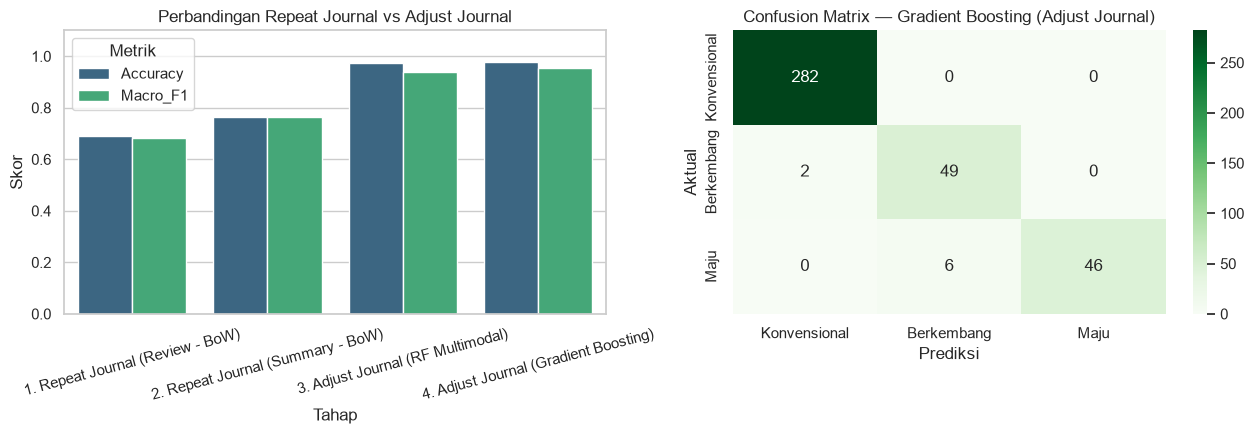

In [4]:
# 4. Penambahan Metode Regression & Perbandingan Repeat Journal vs Adjust Journal
yr_t, yr_p = [], []
for tr, te in gkf.split(X, y_reg, groups):
    reg = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42).fit(X[tr], y_reg[tr])
    yr_t.extend(y_reg[te]); yr_p.extend(reg.predict(X[te]))
print(f'Random Forest Regressor (GroupKFold) -> R2: {r2_score(yr_t, yr_p):.4f} | RMSE: {np.sqrt(mean_squared_error(yr_t, yr_p)):.4f}')

df_comp = pd.read_csv(ROOT / 'peta-digital-umkm' / 'reports' / 'journal_adjust' / 'adjust_vs_repeat_comparison.csv')
display(df_comp)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
melted = df_comp.melt(id_vars='Tahap', value_vars=['Accuracy', 'Macro_F1'], var_name='Metrik', value_name='Skor')
sns.barplot(data=melted, x='Tahap', y='Skor', hue='Metrik', palette='viridis', ax=axes[0])
axes[0].set_title('Perbandingan Repeat Journal vs Adjust Journal')
axes[0].set_ylim(0, 1.1)
axes[0].tick_params(axis='x', rotation=15)

sns.heatmap(best_cm, annot=True, fmt='d', cmap='Greens', xticklabels=list(LABEL_NAMES.values()), yticklabels=list(LABEL_NAMES.values()), ax=axes[1])
axes[1].set_title('Confusion Matrix — Gradient Boosting (Adjust Journal)')
axes[1].set_xlabel('Prediksi'); axes[1].set_ylabel('Aktual')
plt.tight_layout()
plt.show()

,kecamatan,total_umkm,qris_rate,ojol_rate,avg_maturity_score,digital_gap_index,rekomendasi_intervensi
0,Gubeng,172,14.53,9.30,11.88,88.12,Prioritas Tinggi (Pendampingan Intensif QRIS &...
1,Gunung Anyar,50,16.00,22.00,14.75,85.25,Prioritas Tinggi (Pendampingan Intensif QRIS &...
2,Tenggilis Mejoyo,42,26.19,14.29,16.80,83.20,Prioritas Tinggi (Pendampingan Intensif QRIS &...
3,Rungkut,59,28.81,18.64,17.65,82.35,Prioritas Tinggi (Pendampingan Intensif QRIS &...
4,Sukolilo,35,31.43,20.00,19.91,80.09,Prioritas Tinggi (Pendampingan Intensif QRIS &...
5,Mulyorejo,27,44.44,22.22,23.97,76.03,Prioritas Menengah (Akselerasi POS Kasir Digital)


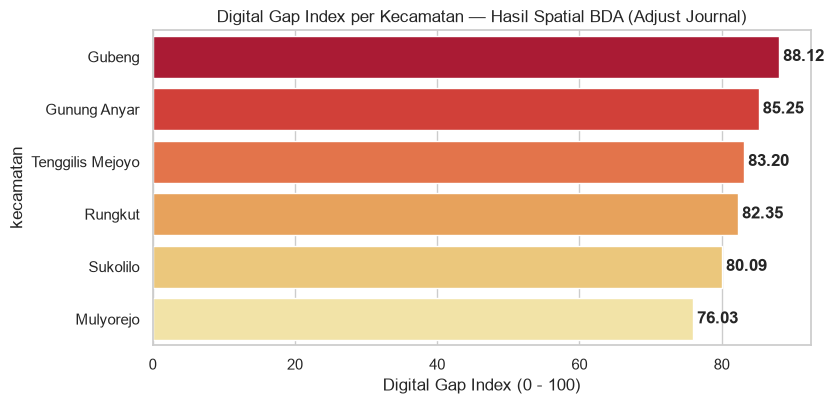

In [5]:
# 5. Penambahan Spatial Big Data Analytics (Digital Gap Index 6 Kecamatan Surabaya Timur)
df_gap = pd.read_csv(ROOT / 'peta-digital-umkm' / 'reports' / 'bda' / 'kecamatan_digital_gap.csv')
display(df_gap[['kecamatan', 'total_umkm', 'qris_rate', 'ojol_rate', 'avg_maturity_score', 'digital_gap_index', 'rekomendasi_intervensi']])

plt.figure(figsize=(8.5, 4.2))
sns.barplot(data=df_gap, x='digital_gap_index', y='kecamatan', hue='kecamatan', palette='YlOrRd_r', legend=False)
plt.title('Digital Gap Index per Kecamatan — Hasil Spatial BDA (Adjust Journal)')
plt.xlabel('Digital Gap Index (0 - 100)')
for i, val in enumerate(df_gap['digital_gap_index']):
    plt.text(val + 0.5, i, f'{val:.2f}', va='center', fontweight='bold')
plt.tight_layout()
plt.show()